# Machine Learning Assignment 2: Bank Marketing Classification

**Dataset:** UCI Bank Marketing (`bank-additional-full.csv`)

**Algorithms:** Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Support Vector Machine.

**Evaluation metrics:** Accuracy, ROC-AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

The dataset should be saved at `data/bank-additional-full.csv` relative to this notebook.

## 1. Import libraries and set project paths

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "bank-additional-full.csv"
MODEL_DIR = PROJECT_DIR / "model"
OUTPUT_DIR = PROJECT_DIR / "outputs"

MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Dataset file exists:", DATA_PATH.exists())

Project folder: C:\BiTS\Sem 2\ML
Dataset path: C:\BiTS\Sem 2\ML\data\bank-additional-full.csv
Dataset file exists: True


## 2. Load the Bank Marketing dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place bank-additional-full.csv inside the data folder. "
        f"Expected location: {DATA_PATH}"
    )

df_original = pd.read_csv(DATA_PATH, sep=";")
print("Dataset loaded successfully.")
print("Original shape:", df_original.shape)
display(df_original.head())

Dataset loaded successfully.
Original shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Initial data inspection

In [3]:
print("Rows:", df_original.shape[0])
print("Columns including target:", df_original.shape[1])
print("Input columns excluding target:", df_original.shape[1] - 1)
print("\nData types and non-null counts:")
df_original.info()
print("\nMissing values by column:")
display(df_original.isnull().sum().to_frame("missing_values"))
print("\nTarget distribution:")
display(df_original["y"].value_counts().to_frame("count"))
display((df_original["y"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))
print("\nExact duplicate rows:", df_original.duplicated().sum())

Rows: 41188
Columns including target: 21
Input columns excluding target: 20

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 n

,missing_values
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0



Target distribution:


,count
y,
no,36548
yes,4640


,percentage
y,
no,88.73
yes,11.27



Exact duplicate rows: 12


## 4. Remove duplicate rows and inspect the target

Exact duplicate records are removed before modelling. The original data is retained in `df_original`.

Exact duplicates removed: 12
Shape after duplicate removal: (41176, 21)


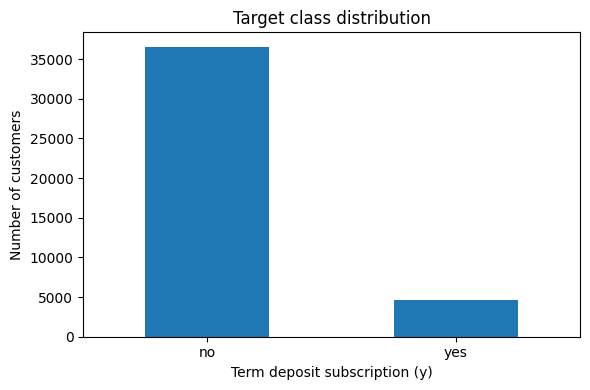

,count,percentage
y,,
no,36537,88.73
yes,4639,11.27


In [4]:
duplicate_count = int(df_original.duplicated().sum())
df = df_original.drop_duplicates().copy()

print("Exact duplicates removed:", duplicate_count)
print("Shape after duplicate removal:", df.shape)

target_counts = df["y"].value_counts()
target_percent = (df["y"].value_counts(normalize=True) * 100).round(2)

fig, ax = plt.subplots(figsize=(6, 4))
target_counts.plot(kind="bar", ax=ax)
ax.set_title("Target class distribution")
ax.set_xlabel("Term deposit subscription (y)")
ax.set_ylabel("Number of customers")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"count": target_counts, "percentage": target_percent}))

## 5. Exploratory data analysis (EDA)

In [5]:
display(df.describe().T)

categorical_columns_all = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Categorical columns:", categorical_columns_all)

for col in ["job", "education", "marital", "contact"]:
    rate = pd.crosstab(df[col], df["y"], normalize="index") * 100
    if "yes" in rate.columns:
        rate = rate.sort_values("yes", ascending=False)
    display(rate.round(1).head(12).style.set_caption(f"Subscription percentage by {col}"))

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


y,no,yes
job,,
student,68.600000,31.400000
retired,74.700000,25.300000
unemployed,85.800000,14.200000
admin.,87.000000,13.000000
management,88.800000,11.200000
unknown,88.800000,11.200000
technician,89.200000,10.800000
self-employed,89.500000,10.500000
housemaid,90.000000,10.000000


y,no,yes
education,,
illiterate,77.800000,22.200000
unknown,85.500000,14.500000
university.degree,86.300000,13.700000
professional.course,88.600000,11.400000
high.school,89.200000,10.800000
basic.4y,89.800000,10.200000
basic.6y,91.800000,8.200000
basic.9y,92.200000,7.800000


y,no,yes
marital,,
unknown,85.000000,15.000000
single,86.000000,14.000000
divorced,89.700000,10.300000
married,89.800000,10.200000


y,no,yes
contact,,
cellular,85.300000,14.700000
telephone,94.800000,5.200000


## 6. Define the predictors and target

The target variable `y` is converted to numeric values: `no` = 0 and `yes` = 1. The `duration` column is excluded because it is measured after the call.

In [6]:
TARGET = "y"
DROP_FROM_FEATURES = ["duration"]  # known only after the call; exclude to avoid target leakage

X = df.drop(columns=[TARGET] + DROP_FROM_FEATURES)
y = df[TARGET].map({"no": 0, "yes": 1})

if y.isna().any():
    raise ValueError("Unexpected target labels found. Expected only 'no' and 'yes'.")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features used:", X.columns.tolist())
print("\nTarget mapping: no = 0, yes = 1")
print(y.value_counts().sort_index())

X shape: (41176, 19)
y shape: (41176,)
Features used: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Target mapping: no = 0, yes = 1
y
0    36537
1     4639
Name: count, dtype: int64


## 7. Split the data

The data is split into training (80%) and testing (20%) sets. Stratification preserves the target-class proportions in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target percentages:")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\nTesting target percentages:")
display((y_test.value_counts(normalize=True) * 100).round(2))

Training rows: 32940
Testing rows: 8236

Training target percentages:


y
0    88.73
1    11.27
Name: proportion, dtype: float64


Testing target percentages:


y
0    88.73
1    11.27
Name: proportion, dtype: float64

## 8. Preprocess the features

Categorical variables are one-hot encoded. Numeric variables are imputed using the median and standardized. Preprocessing is included in each model pipeline and fitted using the training data.

In [8]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

def make_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("Categorical features:", categorical_features)

Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical feature count: 10
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## 9. Define the five required classifiers

In [9]:
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", min_samples_leaf=5
    ),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(
        probability=True, class_weight="balanced", random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("classifier", estimator)
    ])
    for name, estimator in classifiers.items()
}

print("Models prepared:", list(pipelines.keys()))

Models prepared: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


## 10. Train and evaluate the models

The positive class (`yes`) is labelled 1. ROC-AUC is calculated using predicted probabilities.

In [10]:
results = []
trained_models = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_probability = pipeline.predict_proba(X_test)[:, 1]

    row = {
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_probability),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }
    results.append(row)
    trained_models[name] = pipeline

metrics_df = pd.DataFrame(results).set_index("ML Model Name")
metrics_df = metrics_df.sort_values("F1 Score", ascending=False)

print("\nModel comparison:")
display(metrics_df.style.format("{:.4f}"))

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Naive Bayes...
Training Support Vector Machine...

Model comparison:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Support Vector Machine,0.8538,0.7851,0.4047,0.6315,0.4933,0.4265
Logistic Regression,0.8303,0.8002,0.3591,0.6455,0.4615,0.3928
Naive Bayes,0.8082,0.7761,0.3199,0.6239,0.4229,0.3478
KNN,0.8894,0.7408,0.5161,0.2931,0.3739,0.3336
Decision Tree,0.7489,0.7101,0.2464,0.5970,0.3489,0.2592


## 11. Confusion matrices and classification reports


Logistic Regression
                  precision    recall  f1-score   support

 No subscription       0.95      0.85      0.90      7308
Yes subscription       0.36      0.65      0.46       928

        accuracy                           0.83      8236
       macro avg       0.65      0.75      0.68      8236
    weighted avg       0.88      0.83      0.85      8236



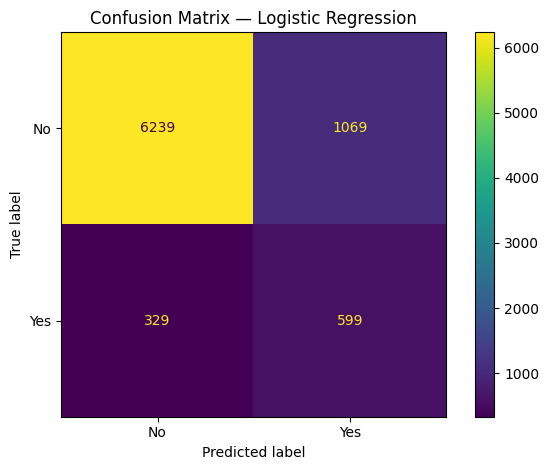


Decision Tree
                  precision    recall  f1-score   support

 No subscription       0.94      0.77      0.84      7308
Yes subscription       0.25      0.60      0.35       928

        accuracy                           0.75      8236
       macro avg       0.59      0.68      0.60      8236
    weighted avg       0.86      0.75      0.79      8236



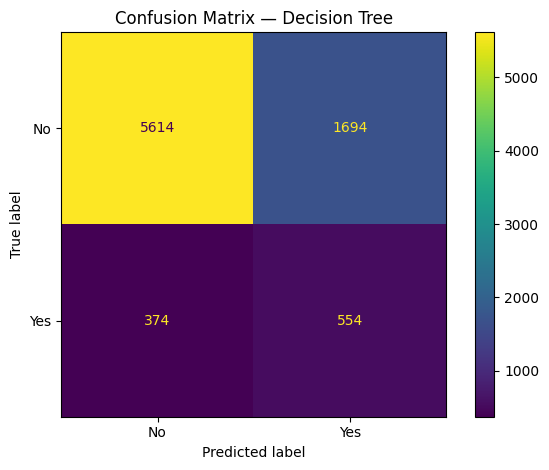


KNN
                  precision    recall  f1-score   support

 No subscription       0.91      0.97      0.94      7308
Yes subscription       0.52      0.29      0.37       928

        accuracy                           0.89      8236
       macro avg       0.72      0.63      0.66      8236
    weighted avg       0.87      0.89      0.88      8236



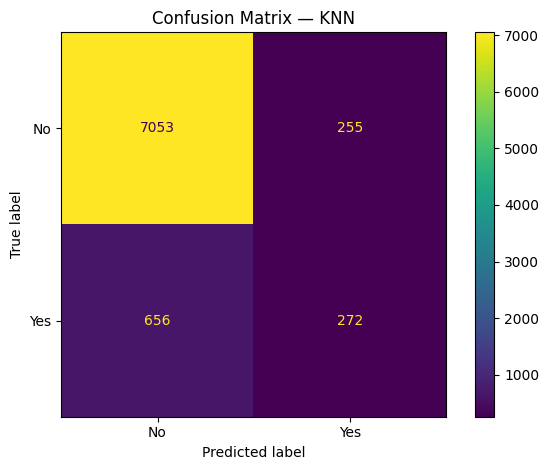


Naive Bayes
                  precision    recall  f1-score   support

 No subscription       0.95      0.83      0.88      7308
Yes subscription       0.32      0.62      0.42       928

        accuracy                           0.81      8236
       macro avg       0.63      0.73      0.65      8236
    weighted avg       0.88      0.81      0.83      8236



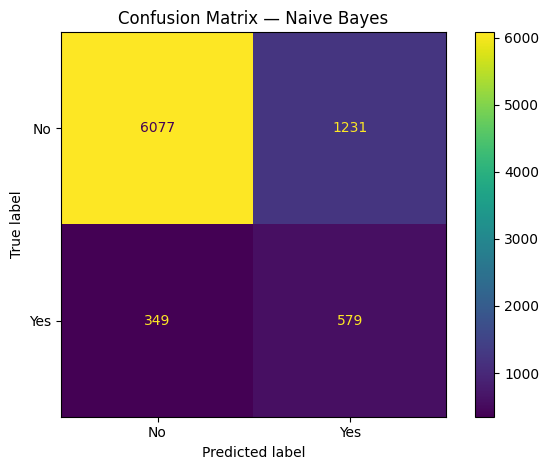


Support Vector Machine
                  precision    recall  f1-score   support

 No subscription       0.95      0.88      0.91      7308
Yes subscription       0.40      0.63      0.49       928

        accuracy                           0.85      8236
       macro avg       0.68      0.76      0.70      8236
    weighted avg       0.89      0.85      0.87      8236



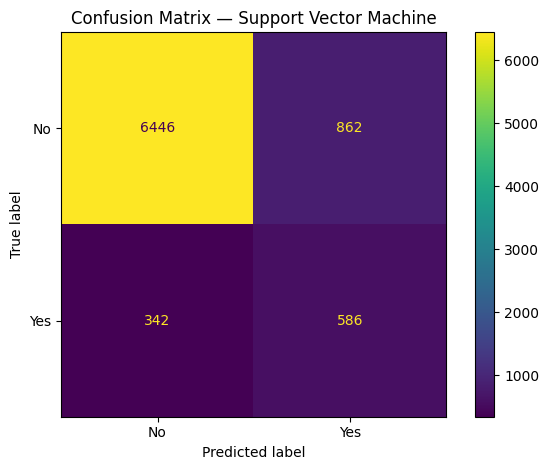

In [11]:
for name, model in trained_models.items():
    predictions = model.predict(X_test)
    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["No subscription", "Yes subscription"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=["No", "Yes"],
        values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 12. Visual model comparison

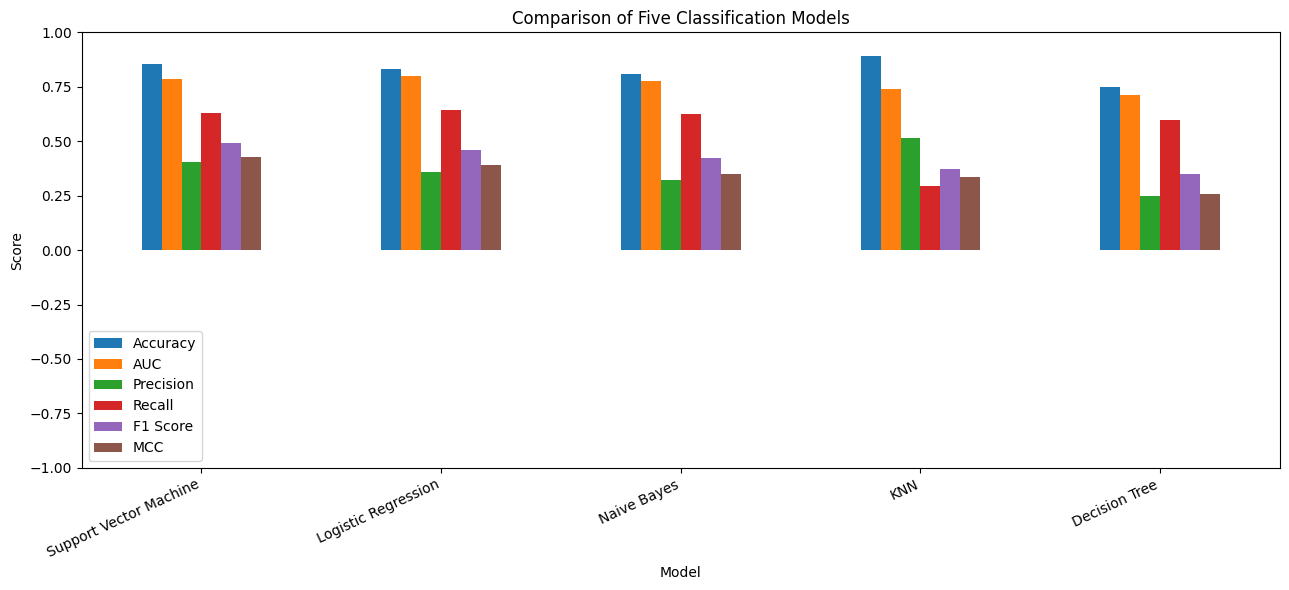

Best model by F1 Score: Support Vector Machine
Best model metrics:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Support Vector Machine,0.8538,0.7851,0.4047,0.6315,0.4933,0.4265


In [12]:
metrics_df.plot(kind="bar", figsize=(13, 6))
plt.title("Comparison of Five Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.ylim(-1, 1)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

best_model_name = metrics_df["F1 Score"].idxmax()
print("Best model by F1 Score:", best_model_name)
print("Best model metrics:")
display(metrics_df.loc[[best_model_name]].style.format("{:.4f}"))

## 13. Compare model performance

The observations below are generated from the evaluation metrics. Review them alongside the confusion matrices when interpreting the results.

In [13]:
observation_rows = []
for model_name, row in metrics_df.iterrows():
    observation_rows.append({
        "ML Model Name": model_name,
        "Observation about model performance": (
            f"Accuracy={row['Accuracy']:.3f}, AUC={row['AUC']:.3f}, "
            f"Precision={row['Precision']:.3f}, Recall={row['Recall']:.3f}, "
            f"F1={row['F1 Score']:.3f}, MCC={row['MCC']:.3f}. "
            "Compare precision and recall to understand the trade-off in identifying "
            "customers who subscribed. Refer to the confusion matrix for false positives "
            "and false negatives."
        )
    })

observations_df = pd.DataFrame(observation_rows)
display(observations_df)
print(
    f"Overall winner by F1 Score: {best_model_name}. "
    "Also consider AUC and MCC before making your final conclusion."
)

,ML Model Name,Observation about model performance
0,Support Vector Machine,"Accuracy=0.854, AUC=0.785, Precision=0.405, Re..."
1,Logistic Regression,"Accuracy=0.830, AUC=0.800, Precision=0.359, Re..."
2,Naive Bayes,"Accuracy=0.808, AUC=0.776, Precision=0.320, Re..."
3,KNN,"Accuracy=0.889, AUC=0.741, Precision=0.516, Re..."
4,Decision Tree,"Accuracy=0.749, AUC=0.710, Precision=0.246, Re..."


Overall winner by F1 Score: Support Vector Machine. Also consider AUC and MCC before making your final conclusion.


## 14. Save the models and results

The test dataset is saved with its true target labels for use in the Streamlit application.

In [14]:
model_files = {}
for name, model in trained_models.items():
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    model_path = MODEL_DIR / f"{safe_name}.joblib"
    joblib.dump(model, model_path)
    model_files[name] = str(model_path)

test_data = X_test.copy()
test_data[TARGET] = y_test.map({0: "no", 1: "yes"})
test_data.to_csv(PROJECT_DIR / "test_data.csv", index=False)

metrics_df.to_csv(OUTPUT_DIR / "model_metrics.csv")
observations_df.to_csv(OUTPUT_DIR / "model_observations.csv", index=False)

with open(OUTPUT_DIR / "model_files.json", "w", encoding="utf-8") as f:
    json.dump(model_files, f, indent=2)

print("Saved model files:")
for name, path in model_files.items():
    print(name, "->", path)
print("\nSaved test_data.csv")
print("Saved metrics and observations in outputs/")

Saved model files:
Logistic Regression -> C:\BiTS\Sem 2\ML\model\logistic_regression.joblib
Decision Tree -> C:\BiTS\Sem 2\ML\model\decision_tree.joblib
KNN -> C:\BiTS\Sem 2\ML\model\knn.joblib
Naive Bayes -> C:\BiTS\Sem 2\ML\model\naive_bayes.joblib
Support Vector Machine -> C:\BiTS\Sem 2\ML\model\support_vector_machine.joblib

Saved test_data.csv
Saved metrics and observations in outputs/


## 15. Streamlit application

The application allows a user to select a trained model, upload labelled test data and view evaluation metrics, a confusion matrix and a classification report.

In [15]:
app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

st.set_page_config(page_title="Bank Marketing Classifier", page_icon="📊", layout="wide")
st.title("Bank Marketing — Classification Model Demo")
st.write(
    "Upload labelled test data, select a trained classifier, and inspect its "
    "evaluation metrics and confusion matrix."
)

BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "model"

MODEL_PATHS = {
    "Logistic Regression": MODEL_DIR / "logistic_regression.joblib",
    "Decision Tree": MODEL_DIR / "decision_tree.joblib",
    "KNN": MODEL_DIR / "knn.joblib",
    "Naive Bayes": MODEL_DIR / "naive_bayes.joblib",
    "Support Vector Machine": MODEL_DIR / "support_vector_machine.joblib",
}

selected_model = st.selectbox("Select a classification model", list(MODEL_PATHS))
uploaded_file = st.file_uploader("Upload test data (CSV)", type=["csv"])

st.caption("A sample held-out test dataset is provided as test_data.csv in the repository.")

if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)
    st.subheader("Uploaded data preview")
    st.dataframe(data.head())

    if "y" not in data.columns:
        st.error("The uploaded CSV must include the target column 'y' (yes/no) to calculate evaluation metrics.")
        st.stop()

    if not MODEL_PATHS[selected_model].exists():
        st.error(f"Model file not found: {MODEL_PATHS[selected_model]}")
        st.stop()

    model = joblib.load(MODEL_PATHS[selected_model])
    X_eval = data.drop(columns=["y"])
    y_true_raw = data["y"].astype(str).str.strip().str.lower()
    mapping = {"no": 0, "yes": 1}
    y_true = y_true_raw.map(mapping)

    if y_true.isna().any():
        st.error("Target column 'y' must contain only 'yes' and 'no'.")
        st.stop()

    try:
        y_pred = model.predict(X_eval)
        y_prob = model.predict_proba(X_eval)[:, 1]
    except Exception as exc:
        st.error(f"Could not evaluate this file. Check that its columns match the training features. Details: {exc}")
        st.stop()

    accuracy = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if len(set(y_true)) == 2 else float("nan")
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)

    st.subheader(f"Evaluation — {selected_model}")
    cols = st.columns(3)
    metrics = [
        ("Accuracy", accuracy), ("AUC", auc), ("Precision", precision),
        ("Recall", recall), ("F1 Score", f1), ("MCC", mcc)
    ]
    for i, (label, value) in enumerate(metrics):
        cols[i % 3].metric(label, f"{value:.4f}" if pd.notna(value) else "N/A")

    st.subheader("Confusion matrix")
    fig, ax = plt.subplots()
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1],
        display_labels=["No", "Yes"], values_format="d", ax=ax
    )
    st.pyplot(fig)

    st.subheader("Classification report")
    report = classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["No subscription", "Yes subscription"],
        output_dict=True, zero_division=0
    )
    st.dataframe(pd.DataFrame(report).transpose().round(4))

    result_download = data.copy()
    result_download["actual_y_numeric"] = y_true
    result_download["predicted_y_numeric"] = y_pred
    result_download["predicted_probability_yes"] = y_prob
    st.download_button(
        "Download predictions CSV",
        result_download.to_csv(index=False).encode("utf-8"),
        file_name="bank_marketing_predictions.csv",
        mime="text/csv"
    )
else:
    st.info("Upload test_data.csv (or another labelled test CSV) to display model results.")
'''

(PROJECT_DIR / "app.py").write_text(app_code, encoding="utf-8")
print("Created app.py")

Created app.py


## 16. Create `requirements.txt`

In [16]:
requirements_text = """streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
"""
(PROJECT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")
print("Created requirements.txt")

Created requirements.txt


## 17. Create a README with the project description and actual metrics

In [17]:
metric_table_md = metrics_df.round(4).to_markdown()

readme_text = f"""# Bank Marketing Classification Project

## a. Problem statement
The objective is to predict whether a bank customer will subscribe to a term deposit (`y`) using customer, campaign, and macroeconomic attributes.

## b. Dataset description
- Source: UCI Machine Learning Repository — Bank Marketing.
- File used: `bank-additional-full.csv`.
- Original dataset: 41,188 records and 20 input features plus the target.
- Target: `y` (`yes` or `no`).
- Exact duplicate rows identified and removed: {duplicate_count}.
- Missing values reported by pandas: {int(df_original.isnull().sum().sum())}.
- The `duration` feature was excluded because it is only known after the call and can cause target leakage in a prospective prediction task.
- After duplicate removal: {len(df)} records.

## c. GitHub Repository Link
Add your GitHub repository URL here after creating and uploading the project.

## d. Models used and evaluation metrics

The data was split into 80% training and 20% testing using stratification. Categorical columns were one-hot encoded. Numeric columns were median-imputed and standardized. Preprocessing was fitted within each model pipeline using training data only.

{metric_table_md}

### Observations about model performance
Use the table above and the confusion matrices in the notebook to write your own observations. Discuss the precision/recall trade-off, AUC, F1-score, and MCC. Do not choose a winner based only on accuracy because the target is imbalanced.

### Overall winner
The model with the highest F1-score on this run is **{best_model_name}**. Review its AUC and MCC as well before finalizing your conclusion.

## Streamlit application
Run locally with:
```bash
streamlit run app.py
```
Upload `test_data.csv` to see the evaluation metrics, confusion matrix, classification report, and downloadable predictions.

## Repository contents
- `app.py`: Streamlit application.
- `requirements.txt`: Python dependencies.
- `README.md`: project description and evaluation results.
- `test_data.csv`: held-out test data with labels.
- `model/`: saved fitted model pipelines.
- `outputs/`: model metrics, observations, and model file list.

## Reproducibility
The notebook uses `random_state=42` for the train/test split and model configurations.
"""

(PROJECT_DIR / "README.md").write_text(readme_text, encoding="utf-8")
print("Created README.md")
print("\nREADME preview:")
print(readme_text[:2500])

Created README.md

README preview:
# Bank Marketing Classification Project

## a. Problem statement
The objective is to predict whether a bank customer will subscribe to a term deposit (`y`) using customer, campaign, and macroeconomic attributes.

## b. Dataset description
- Source: UCI Machine Learning Repository — Bank Marketing.
- File used: `bank-additional-full.csv`.
- Original dataset: 41,188 records and 20 input features plus the target.
- Target: `y` (`yes` or `no`).
- Exact duplicate rows identified and removed: 12.
- Missing values reported by pandas: 0.
- The `duration` feature was excluded because it is only known after the call and can cause target leakage in a prospective prediction task.
- After duplicate removal: 41176 records.

## c. GitHub Repository Link
Add your GitHub repository URL here after creating and uploading the project.

## d. Models used and evaluation metrics

The data was split into 80% training and 20% testing using stratification. Categorical columns 

## 18. Project files

The notebook creates the trained models, evaluation outputs, `app.py`, `requirements.txt` and `README.md`.

To run the application from the project folder:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

The GitHub repository, deployed application URL and required BITS Virtual Lab screenshot should be added before submission.